# **Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from keras.models import Sequential
from keras.layers import Dense, LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# **Upload Dataset**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving AirPassengers.csv to AirPassengers.csv


# **Load Dataset**

In [ ]:
data = pd.read_csv("AirPassengers.csv")

print(data.head())

     Month  #Passengers
0  1949-01          112
1  1949-02          118
2  1949-03          132
3  1949-04          129
4  1949-05          121


# **Visualize Dataset**

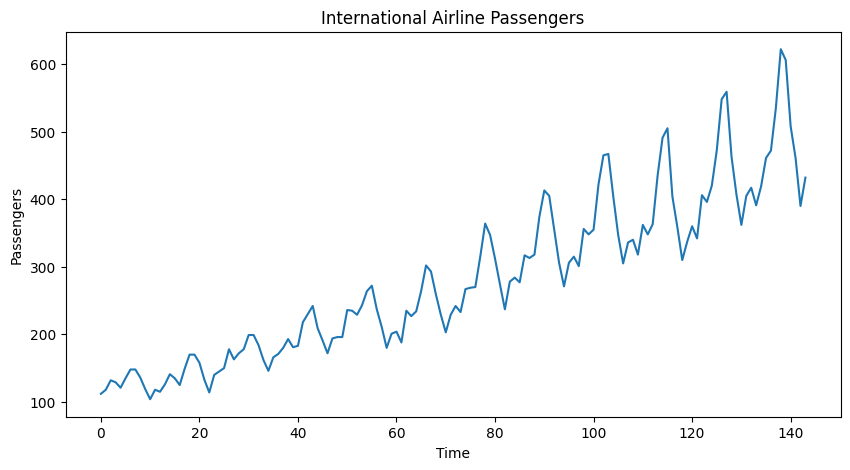

In [ ]:
dataset = data.iloc[:,1].values

plt.figure(figsize=(10,5))
plt.plot(dataset)
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.title("International Airline Passengers")
plt.show()

# **Data Preprocessing**

In [ ]:
dataset = dataset.reshape(-1,1)
dataset = dataset.astype('float32')

scaler = MinMaxScaler(feature_range=(0,1))
dataset = scaler.fit_transform(dataset)

# 80% Train, 20% Test
train_size = int(len(dataset) * 0.8)

train = dataset[:train_size]
test = dataset[train_size:]

print("Train Size:", len(train))
print("Test Size:", len(test))

Train Size: 115
Test Size: 29


# **Create Dataset Function**

In [ ]:
def create_dataset(data, time_step):

    X = []
    Y = []

    for i in range(len(data)-time_step-1):

        X.append(data[i:(i+time_step),0])
        Y.append(data[i+time_step,0])

    return np.array(X), np.array(Y)

# **Create Sequences**

In [ ]:
time_step = 12

trainX, trainY = create_dataset(train, time_step)
testX, testY = create_dataset(test, time_step)

trainX = trainX.reshape(
    trainX.shape[0],
    1,
    trainX.shape[1]
)

testX = testX.reshape(
    testX.shape[0],
    1,
    testX.shape[1]
)

print(trainX.shape)
print(trainY.shape)
print(testX.shape)
print(testY.shape)

(102, 1, 12)
(102,)
(16, 1, 12)
(16,)


# **Build Improved LSTM Model**

In [ ]:
model = Sequential()

model.add(
    LSTM(
        32,
        input_shape=(1,time_step)
    )
)

model.add(Dense(1))

model.compile(
    loss='mean_squared_error',
    optimizer='adam'
)

history = model.fit(
    trainX,
    trainY,
    epochs=50,
    batch_size=1,
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


102/102 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0139
Epoch 2/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0045
Epoch 3/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0035
Epoch 4/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0032
Epoch 5/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0027
Epoch 6/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0023
Epoch 7/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0022
Epoch 8/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0019
Epoch 9/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0018
Epoch 10/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0016
Epoch 11/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0015
Epoch 12/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0012
Epoch 13/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0012
Epoch 14/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0010    
Epoch 15/50
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0

# **Predictions**

In [ ]:
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

trainPredict = scaler.inverse_transform(trainPredict)
testPredict = scaler.inverse_transform(testPredict)

trainY = scaler.inverse_transform([trainY])
testY = scaler.inverse_transform([testY])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


In [ ]:
trainY = trainY.reshape(-1)
testY = testY.reshape(-1)

print(trainY.shape)
print(testY.shape)

(102,)
(16,)


# **Calculate RMSE**

In [ ]:
trainScore = math.sqrt(
    mean_squared_error(
        trainY,
        trainPredict[:,0]
    )
)

testScore = math.sqrt(
    mean_squared_error(
        testY,
        testPredict[:,0]
    )
)

print("Train Score: %.2f RMSE" % trainScore)
print("Test Score: %.2f RMSE" % testScore)

Train Score: 14.89 RMSE
Test Score: 23.70 RMSE


# **Plot Predictions**

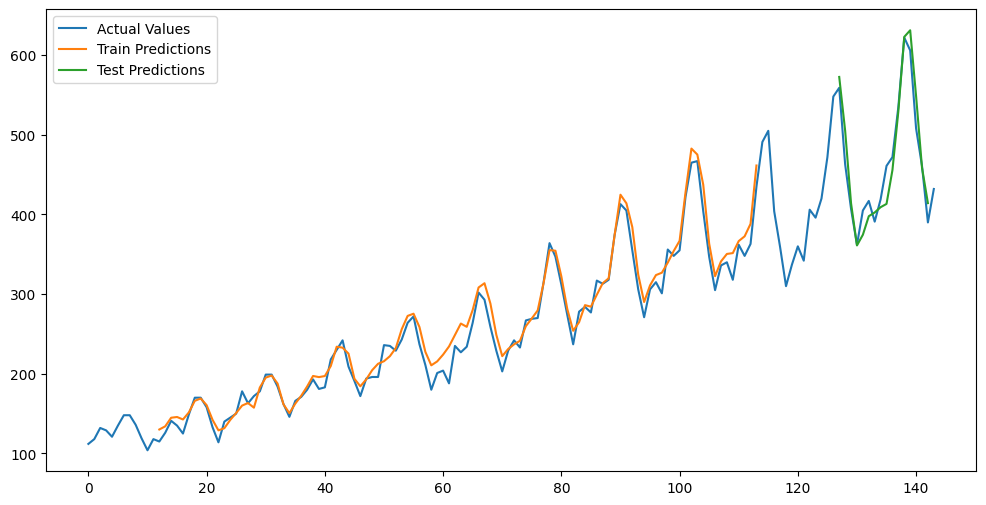

In [ ]:
trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan

trainPredictPlot[
    time_step:len(trainPredict)+time_step,
    :
] = trainPredict

testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan

testPredictPlot[
    len(trainPredict)+(time_step*2)+1:
    len(dataset)-1,
    :
] = testPredict

plt.figure(figsize=(12,6))

plt.plot(
    scaler.inverse_transform(dataset),
    label="Actual Values"
)

plt.plot(
    trainPredictPlot,
    label="Train Predictions"
)

plt.plot(
    testPredictPlot,
    label="Test Predictions"
)

plt.legend()
plt.show()

# **Predict Next 10 Future Values**

In [ ]:
future_predictions = []

last_sequence = test[-time_step:].flatten().tolist()

for i in range(10):

    x_input = np.array(
        last_sequence[-time_step:]
    )

    x_input = x_input.reshape(
        (1,1,time_step)
    )

    pred = model.predict(
        x_input,
        verbose=0
    )

    future_predictions.append(
        pred[0][0]
    )

    last_sequence.append(
        pred[0][0]
    )

# **Convert Back to Passenger Numbers**

In [ ]:
future_predictions = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1,1)
)

print("Next 10 Future Passenger Predictions:")

for i,value in enumerate(future_predictions):

    print(
        "Month",
        i+1,
        ":",
        round(value[0],2)
    )

Next 10 Future Passenger Predictions:
Month 1 : 443.81
Month 2 : 422.56
Month 3 : 421.68
Month 4 : 447.0
Month 5 : 474.12
Month 6 : 570.02
Month 7 : 680.81
Month 8 : 684.25
Month 9 : 608.81
Month 10 : 522.26


# **Plot Future Forecast**

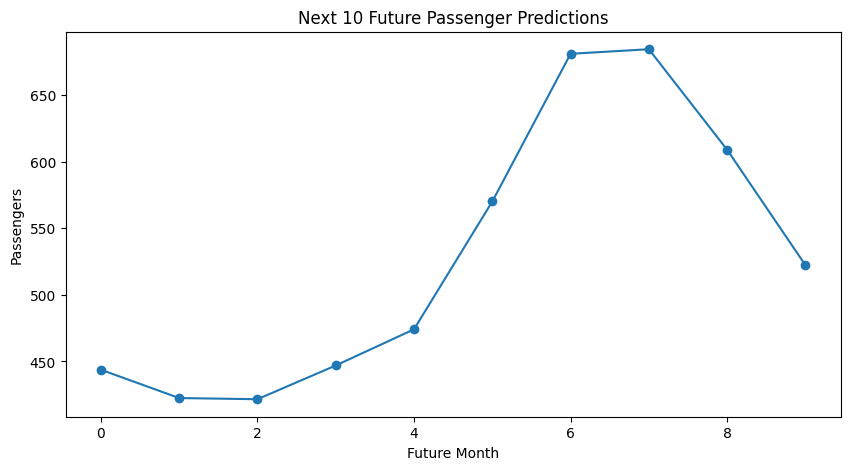

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    future_predictions,
    marker='o'
)

plt.title("Next 10 Future Passenger Predictions")

plt.xlabel("Future Month")
plt.ylabel("Passengers")

plt.show()